# in the name of God
**machine learning final project**

**prof. Hamed Baghban**

**stud. MohammadMahdi Faraji [student ID removed]**


# check the class in dateset:

In [ ]:
# دانلود داده‌ها از Google
!wget http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz

# استخراج فایل‌ها
import tarfile
with tarfile.open('speech_commands_v0.02.tar.gz', 'r:gz') as tar:
    tar.extractall('speech_commands')


--2025-01-26 17:40:15--  http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
Resolving download.tensorflow.org (download.tensorflow.org)... 74.125.195.207, 172.253.117.207, 142.250.99.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|74.125.195.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2428923189 (2.3G) [application/gzip]
Saving to: ‘speech_commands_v0.02.tar.gz’

speech_commands_v0. 100%[===================>]   2.26G   195MB/s    in 23s     

2025-01-26 17:40:38 (102 MB/s) - ‘speech_commands_v0.02.tar.gz’ saved [2428923189/2428923189]



# check the class in dateset:

In [ ]:
import os

# بررسی محتویات داده‌ها
data_path = 'speech_commands'
classes = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d))]
print(f"Classes ({len(classes)}): {classes}")


Classes (36): ['zero', 'seven', 'go', 'one', 'bed', 'stop', 'three', 'nine', 'bird', 'tree', 'no', 'down', 'two', 'backward', 'six', 'sheila', 'forward', 'happy', 'left', 'cat', 'learn', 'follow', 'dog', 'house', 'four', '_background_noise_', 'wow', 'up', 'marvin', 'off', 'on', 'visual', 'eight', 'five', 'yes', 'right']


# select the desired class:

In [ ]:
import shutil

# لیست کلاس‌های انتخابی
selected_classes = ['yes', 'no', 'right', 'left']
filtered_data_dir = 'filtered_speech_commands'

# ایجاد پوشه جدید برای داده‌های انتخابی
os.makedirs(filtered_data_dir, exist_ok=True)

for class_name in selected_classes:
    src_dir = os.path.join(data_path, class_name)
    dst_dir = os.path.join(filtered_data_dir, class_name)
    os.makedirs(dst_dir, exist_ok=True)

    # کپی فایل‌های هر کلاس به پوشه جدید
    for file_name in os.listdir(src_dir):
        full_file_name = os.path.join(src_dir, file_name)
        if os.path.isfile(full_file_name):
            shutil.copy(full_file_name, dst_dir)

print(f"داده‌های مربوط به کلاس‌های {selected_classes} جدا شدند.")


داده‌های مربوط به کلاس‌های ['yes', 'no', 'right', 'left'] جدا شدند.


# num of data

In [ ]:
for class_name in selected_classes:
    class_dir = os.path.join(filtered_data_dir, class_name)
    num_files = len(os.listdir(class_dir))
    print(f"{class_name}: {num_files} فایل")


yes: 4044 فایل
no: 3941 فایل
right: 3778 فایل
left: 3801 فایل


# extract features

In [ ]:
import librosa
import numpy as np
import os
import pandas as pd

def extract_features(file_path, n_mfcc=13, max_pad_len=50):
    try:
        audio, sample_rate = librosa.load(file_path, sr=None)
        mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)
        # پد کردن یا برش برای یکسان‌سازی طول
        if mfcc.shape[1] < max_pad_len:
            pad_width = max_pad_len - mfcc.shape[1]
            mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode='constant')
        else:
            mfcc = mfcc[:, :max_pad_len]
        return mfcc.flatten()
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# مسیر داده‌ها
data_dir = 'filtered_speech_commands'
labels = []
features = []

for class_name in ['yes', 'no', 'right', 'left']:
    class_dir = os.path.join(data_dir, class_name)
    for file_name in os.listdir(class_dir):
        file_path = os.path.join(class_dir, file_name)
        feature = extract_features(file_path)
        if feature is not None:
            features.append(feature)
            labels.append(class_name)

# تبدیل به آرایه numpy
X = np.array(features)
y = np.array(labels)

# تبدیل به DataFrame برای ذخیره‌سازی در فایل CSV
df = pd.DataFrame(X)
df['label'] = y

# ذخیره‌سازی در فایل CSV
df.to_csv('features_with_labels.csv', index=False)

print("ویژگی‌ها و برچسب‌ها در فایل CSV ذخیره شدند.")


ویژگی‌ها و برچسب‌ها در فایل CSV ذخیره شدند.


# building model and train

In [ ]:
from sklearn.preprocessing import LabelEncoder

# تبدیل برچسب‌ها به اعداد
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
print("برچسب‌ها به اعداد تبدیل شدند:", encoder.classes_)


برچسب‌ها به اعداد تبدیل شدند: ['left' 'no' 'right' 'yes']


In [ ]:
from sklearn.preprocessing import StandardScaler

# مقیاس‌بندی داده‌ها
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("داده‌ها مقیاس‌بندی شدند.")

داده‌ها مقیاس‌بندی شدند.


In [ ]:
from sklearn.preprocessing import StandardScaler

# مقیاس‌بندی داده‌ها
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("داده‌ها مقیاس‌بندی شدند.")


داده‌ها مقیاس‌بندی شدند.


In [ ]:
from sklearn.model_selection import train_test_split

# تقسیم داده‌ها به آموزش و اعتبارسنجی
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)
print("داده‌ها به آموزش و اعتبارسنجی تقسیم شدند.")


داده‌ها به آموزش و اعتبارسنجی تقسیم شدند.


In [ ]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers, models, regularizers, optimizers
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# مدل با تنظیم نرخ یادگیری
learning_rate = 0.00005  # مقدار دلخواه نرخ یادگیری
optimizer = optimizers.Adam(learning_rate=learning_rate)

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.3),
    layers.Dense(len(np.unique(y_train)), activation='softmax')
])

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# آموزش مدل
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping]
)

# ذخیره مدل
model.save('modele.h5')

# ارزیابی نهایی
loss, accuracy = model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss}, Validation Accuracy: {accuracy}")


Epoch 1/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.2829 - loss: 4.5197 - val_accuracy: 0.5612 - val_loss: 3.6365
Epoch 2/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4521 - loss: 3.6686 - val_accuracy: 0.6614 - val_loss: 3.1403
Epoch 3/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5504 - loss: 3.2109 - val_accuracy: 0.7022 - val_loss: 2.8213
Epoch 4/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6007 - loss: 2.9079 - val_accuracy: 0.7253 - val_loss: 2.5914
Epoch 5/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6526 - loss: 2.6556 - val_accuracy: 0.7453 - val_loss: 2.4132
Epoch 6/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6791 - loss: 2.4851 - val_accuracy: 0.7623 - val_loss: 2.2618
Epoch 7/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6883 - loss: 2.3460 - val_accuracy: 0.7735 - val_loss: 2.1283
Epoch 8/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7179 - loss: 2.1905 - val_accu

# the plots of loss and accuracy

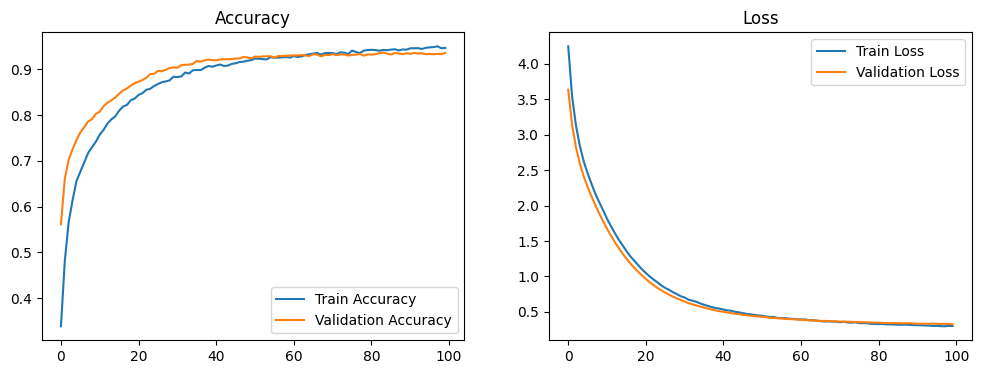

In [ ]:
import matplotlib.pyplot as plt

# رسم دقت و خطا
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')
plt.show()


# Confusion Matrix

98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


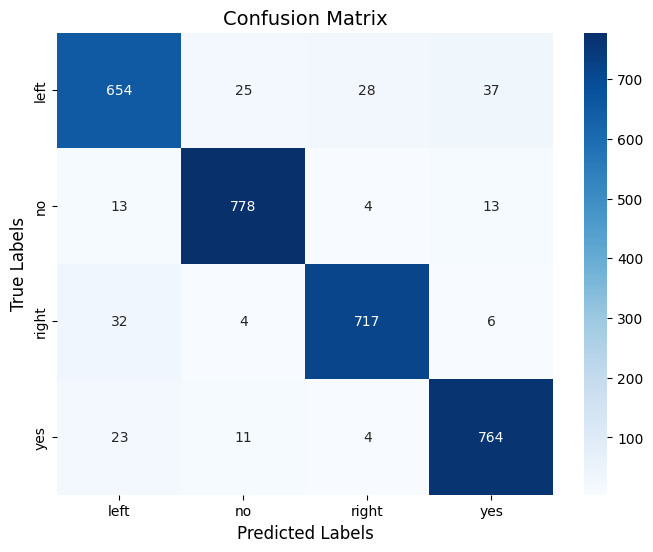


Classification Report:
              precision    recall  f1-score   support

        left       0.91      0.88      0.89       744
          no       0.95      0.96      0.96       808
       right       0.95      0.94      0.95       759
         yes       0.93      0.95      0.94       802

    accuracy                           0.94      3113
   macro avg       0.94      0.93      0.93      3113
weighted avg       0.94      0.94      0.94      3113



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# پیش‌بینی روی داده‌های اعتبارسنجی
y_pred = np.argmax(model.predict(X_val), axis=1)

# محاسبه Confusion Matrix
cm = confusion_matrix(y_val, y_pred)

# نمایش ماتریس Confusion Matrix با ابعاد و رنگ دلخواه
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

# گزارش عملکرد
print("\nClassification Report:")
print(classification_report(y_val, y_pred, target_names=encoder.classes_))


# upload the zip of test voice

In [ ]:
from google.colab import files
uploaded = files.upload()




Saving testt.zip to testt.zip


# extracting new test voice

In [ ]:
import zipfile
import os

# Extract the uploaded ZIP file
with zipfile.ZipFile('testt.zip', 'r') as zip_ref:
    zip_ref.extractall('testt')

# Check the extracted files
os.listdir('testt')

['right_4.wav',
 'yes_3.wav',
 'left_6.wav',
 'yes_1.wav',
 'right_2.wav',
 'no_6.wav',
 'no_5.wav',
 'no_8.wav',
 'right_5.wav',
 'no_3.wav',
 'yes_4.wav',
 'left_5.wav',
 'left_1.wav',
 'right_1.wav',
 'right_6.wav',
 'no_4.wav',
 'yes_2.wav',
 'left_7.wav',
 'right_3.wav',
 'right_7.wav',
 'left_4.wav',
 'yes_5.wav',
 'left_2.wav',
 'left_3.wav',
 'no_7.wav',
 'no_9.wav',
 'yes_6.wav',
 'yes_7.wav']

# test the model with test voice

In [ ]:
import pandas as pd
from tensorflow.keras.models import load_model

# بارگذاری مدل ذخیره‌شده
model = load_model('modele.h5')

# مسیر فایل‌های آزمایشی
test_files_dir = '/content/testt'

# تابع استخراج ویژگی مشابه مدل
def extract_features_for_test(file_path, n_mfcc=13, max_pad_len=50):
    try:
        audio, sample_rate = librosa.load(file_path, sr=None)
        mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)
        if mfcc.shape[1] < max_pad_len:
            pad_width = max_pad_len - mfcc.shape[1]
            mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode='constant')
        else:
            mfcc = mfcc[:, :max_pad_len]
        return mfcc.flatten()
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# پیش‌بینی برای فایل‌های آزمایشی
predictions = []
for file_name in os.listdir(test_files_dir):
    file_path = os.path.join(test_files_dir, file_name)
    feature = extract_features_for_test(file_path)
    if feature is not None:
        feature_scaled = scaler.transform([feature])  # نرمال‌سازی
        pred_class = encoder.inverse_transform([np.argmax(model.predict(feature_scaled))])[0]
        predictions.append({'File Name': file_name, 'Predicted Class': pred_class})

# نمایش نتایج در قالب جدول
results_df = pd.DataFrame(predictions)
print(results_df)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━

# to .tflite

In [ ]:
import tensorflow as tf

# بارگذاری مدل ذخیره شده
model = tf.keras.models.load_model("modele.h5")

# تبدیل مدل به TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# ذخیره مدل TFLite
with open("modele.tflite", "wb") as f:
    f.write(tflite_model)

print("مدل به فرمت TFLite تبدیل و ذخیره شد به نام 'modele.tflite'")


Saved artifact at '/tmp/tmpn5u6brds'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 650), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  133711731979280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133711731975824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133711719510480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133711719507216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133711719509520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133711719511440: TensorSpec(shape=(), dtype=tf.resource, name=None)
مدل به فرمت TFLite تبدیل و ذخیره شد به نام 'modele.tflite'


# to (.h) file

In [ ]:
!xxd -i modele.tflite > modele.h


# download (.h) file

In [ ]:
from google.colab import files
files.download('modele.h')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>